## Student Performance Indicator


#### Life cycle of Machine learning Project

- Understanding the Problem Statement
- Data Collection
- Data Checks to perform
- Exploratory data analysis
- Data Pre-Processing
- Model Training
- Choose best model

### 1) Problem statement
- This project understands how the student's performance (test scores) is affected by other variables such as Gender, Ethnicity, Parental level of education, Lunch and Test preparation course.


### 2) Data Collection
- Dataset Source - https://www.kaggle.com/datasets/spscientist/students-performance-in-exams?datasetId=74977
- The data consists of 8 column and 1000 rows.

### 2.1 Import Data and Required Packages
####  Importing Pandas, Numpy, Matplotlib, Seaborn and Warings Library.

In [36]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

#### Import the CSV Data as Pandas DataFrame

In [37]:
df = pd.read_csv('data/stud.csv')

#### Show Top 5 Records

In [38]:
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


#### Shape of the dataset

In [39]:
df.shape

(1000, 8)

### 2.2 Dataset information

- gender : sex of students  -> (Male/female)
- race/ethnicity : ethnicity of students -> (Group A, B,C, D,E)
- parental level of education : parents' final education ->(bachelor's degree,some college,master's degree,associate's degree,high school)
- lunch : having lunch before test (standard or free/reduced) 
- test preparation course : complete or not complete before test
- math score
- reading score
- writing score

### 3. Data Checks to perform

- Check Missing values
- Check Duplicates
- Check data type
- Check the number of unique values of each column
- Check statistics of data set
- Check various categories present in the different categorical column

### 3.1 Check Missing values

In [40]:
df.isna().sum()

gender                         0
race_ethnicity                 0
parental_level_of_education    0
lunch                          0
test_preparation_course        0
math_score                     0
reading_score                  0
writing_score                  0
dtype: int64

#### There are no missing values in the data set

### 3.2 Check Duplicates

In [41]:
df.duplicated().sum()

np.int64(0)

#### There are no duplicates  values in the data set

### 3.3 Check data types

In [42]:
# Check Null and Dtypes
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race_ethnicity               1000 non-null   str  
 2   parental_level_of_education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test_preparation_course      1000 non-null   str  
 5   math_score                   1000 non-null   int64
 6   reading_score                1000 non-null   int64
 7   writing_score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


### 3.4 Checking the number of unique values of each column

In [43]:
df.nunique()

gender                          2
race_ethnicity                  5
parental_level_of_education     6
lunch                           2
test_preparation_course         2
math_score                     81
reading_score                  72
writing_score                  77
dtype: int64

### 3.5 Check statistics of data set

In [44]:
df.describe()

,math_score,reading_score,writing_score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


#### Insight
- From above description of numerical data, all means are very close to each other - between 66 and 68.05;
- All standard deviations are also close - between 14.6 and 15.19;
- While there is a minimum score  0 for math, for writing minimum is much higher = 10 and for reading myet higher = 17

### 3.7 Exploring Data

In [45]:
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [46]:
print("Categories in 'gender' variable:     ",end=" " )
print(df['gender'].unique())

print("Categories in 'race_ethnicity' variable:  ",end=" ")
print(df['race_ethnicity'].unique())

print("Categories in'parental level of education' variable:",end=" " )
print(df['parental_level_of_education'].unique())

print("Categories in 'lunch' variable:     ",end=" " )
print(df['lunch'].unique())

print("Categories in 'test preparation course' variable:     ",end=" " )
print(df['test_preparation_course'].unique())

Categories in 'gender' variable:      <StringArray>
['female', 'male']
Length: 2, dtype: str
Categories in 'race_ethnicity' variable:   <StringArray>
['group B', 'group C', 'group A', 'group D', 'group E']
Length: 5, dtype: str
Categories in'parental level of education' variable: <StringArray>
[ 'bachelor's degree',       'some college',    'master's degree',
 'associate's degree',        'high school',   'some high school']
Length: 6, dtype: str
Categories in 'lunch' variable:      <StringArray>
['standard', 'free/reduced']
Length: 2, dtype: str
Categories in 'test preparation course' variable:      <StringArray>
['none', 'completed']
Length: 2, dtype: str


In [47]:
# define numerical & categorical columns
numeric_features = df.select_dtypes(include=['number']).columns.tolist()
categorical_features = df.select_dtypes(include=['object', 'category']).columns.tolist()

# print columns
print('We have {} numerical features : {}'.format(len(numeric_features), numeric_features))
print('\nWe have {} categorical features : {}'.format(len(categorical_features), categorical_features))

We have 3 numerical features : ['math_score', 'reading_score', 'writing_score']

We have 5 categorical features : ['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course']


In [48]:
df.head(2)

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88


### 3.8 Adding columns for "Total Score" and "Average"

In [49]:
df['total score'] = df['math_score'] + df['reading_score'] + df['writing_score']
df['average'] = df['total score']/3
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,total score,average
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.666667
1,female,group C,some college,standard,completed,69,90,88,247,82.333333
2,female,group B,master's degree,standard,none,90,95,93,278,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.333333
4,male,group C,some college,standard,none,76,78,75,229,76.333333


In [50]:
reading_full = df[df['reading_score'] == 100]['average'].count()
writing_full = df[df['writing_score'] == 100]['average'].count()
math_full = df[df['math_score'] == 100]['average'].count()

print(f'Number of students with full marks in Maths: {math_full}')
print(f'Number of students with full marks in Writing: {writing_full}')
print(f'Number of students with full marks in Reading: {reading_full}')

Number of students with full marks in Maths: 7
Number of students with full marks in Writing: 14
Number of students with full marks in Reading: 17


In [51]:
reading_less_20 = df[df['reading_score'] <= 20]['average'].count()
writing_less_20 = df[df['writing_score'] <= 20]['average'].count()
math_less_20 = df[df['math_score'] <= 20]['average'].count()

print(f'Number of students with less than 20 marks in Maths: {math_less_20}')
print(f'Number of students with less than 20 marks in Writing: {writing_less_20}')
print(f'Number of students with less than 20 marks in Reading: {reading_less_20}')

Number of students with less than 20 marks in Maths: 4
Number of students with less than 20 marks in Writing: 3
Number of students with less than 20 marks in Reading: 1


#####  Insights
 - From above values we get students have performed the worst in Maths 
 - Best performance is in reading section

### 4. Exploring Data ( Visualization )
#### 4.1 Visualize average score distribution to make some conclusion. 
- Histogram
- Kernel Distribution Function (KDE)

#### 4.1.1 Histogram & KDE

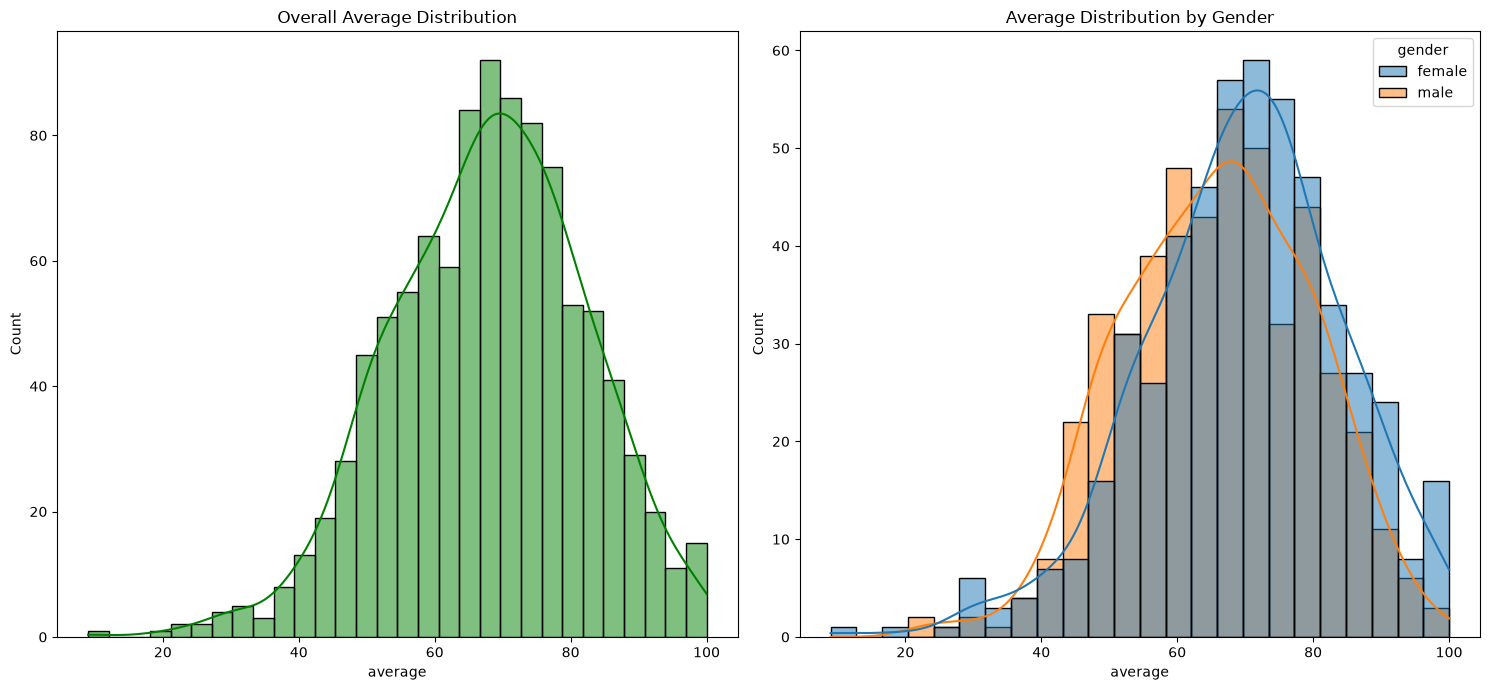

In [52]:
fig, axs = plt.subplots(1, 2, figsize=(15, 7))

# General distribution
sns.histplot(data=df, x='average', bins=30, kde=True, color='g', ax=axs[0])
axs[0].set_title('Overall Average Distribution')

# Distribution by gender
sns.histplot(data=df, x='average', kde=True, hue='gender', ax=axs[1])
axs[1].set_title('Average Distribution by Gender')

plt.tight_layout()
plt.show()

#####  Insights
- Female students tend to perform better than male students.

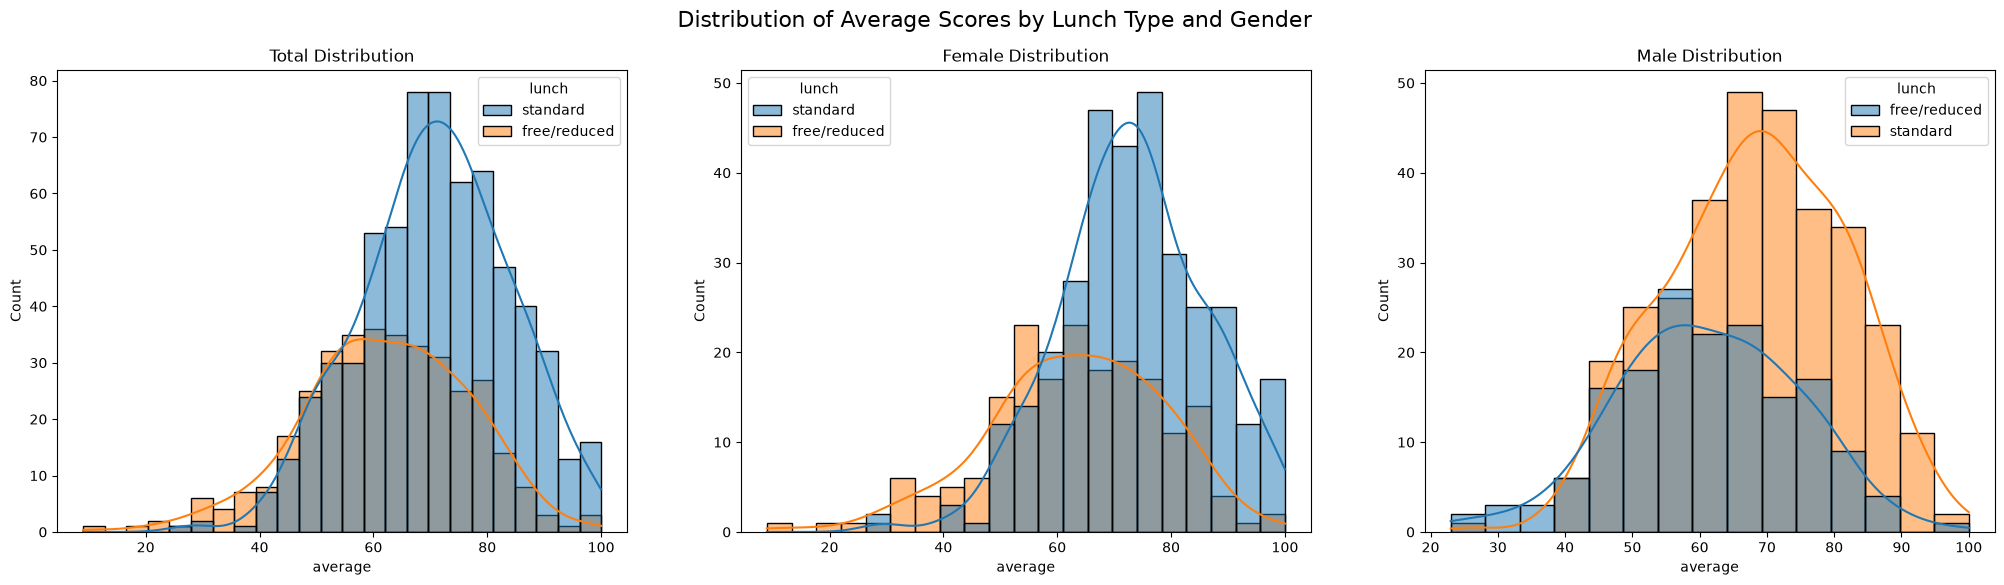

In [53]:
plt.subplots(1, 3, figsize=(25, 6))

plt.subplot(131)
sns.histplot(data=df, x='average', kde=True, hue='lunch')
plt.title('Total Distribution')

plt.subplot(132)
sns.histplot(data=df[df.gender == 'female'], x='average', kde=True, hue='lunch')
plt.title('Female Distribution')

plt.subplot(133)
sns.histplot(data=df[df.gender == 'male'], x='average', kde=True, hue='lunch')
plt.title('Male Distribution')

# Título general para todo el trío
plt.suptitle('Distribution of Average Scores by Lunch Type and Gender', fontsize=16)
plt.show()

#####  Insights
- Standard lunch helps perform well in exams.
- Standard lunch helps perform well in exams be it a male or a female.

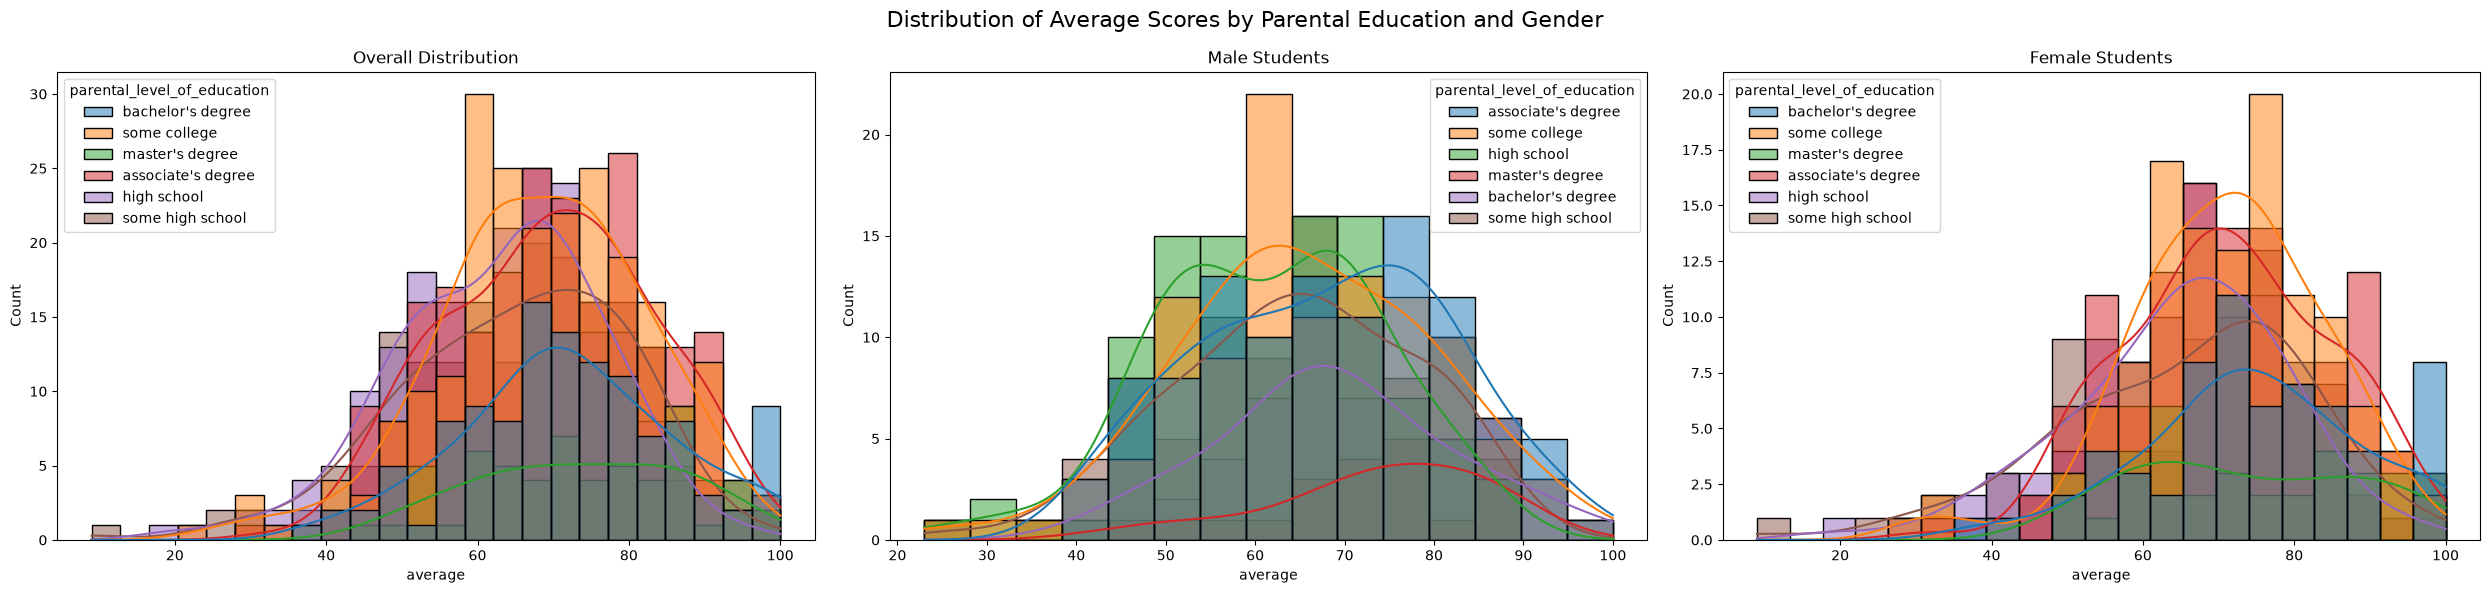

In [54]:
fig, axs = plt.subplots(1, 3, figsize=(25, 6))

# Plot 1: Overall population distribution by parental level of education
sns.histplot(data=df, x='average', kde=True, hue='parental_level_of_education', ax=axs[0])
axs[0].set_title('Overall Distribution')

# Plot 2: Male students distribution by parental level of education
sns.histplot(data=df[df.gender == 'male'], x='average', kde=True, hue='parental_level_of_education', ax=axs[1])
axs[1].set_title('Male Students')

# Plot 3: Female students distribution by parental level of education
sns.histplot(data=df[df.gender == 'female'], x='average', kde=True, hue='parental_level_of_education', ax=axs[2])
axs[2].set_title('Female Students')

# Add overall title and optimize layout
plt.suptitle('Distribution of Average Scores by Parental Education and Gender', fontsize=16)
plt.tight_layout()
plt.show()

#####  Insights
- In general parent's education doesn't affect students' performance.
- 2nd plot shows that parents whose education is of associate's degree or master's degree their male child tends to perform well in his exams.
- In the 3rd plot we can see there is no effect from parent's education on female students.

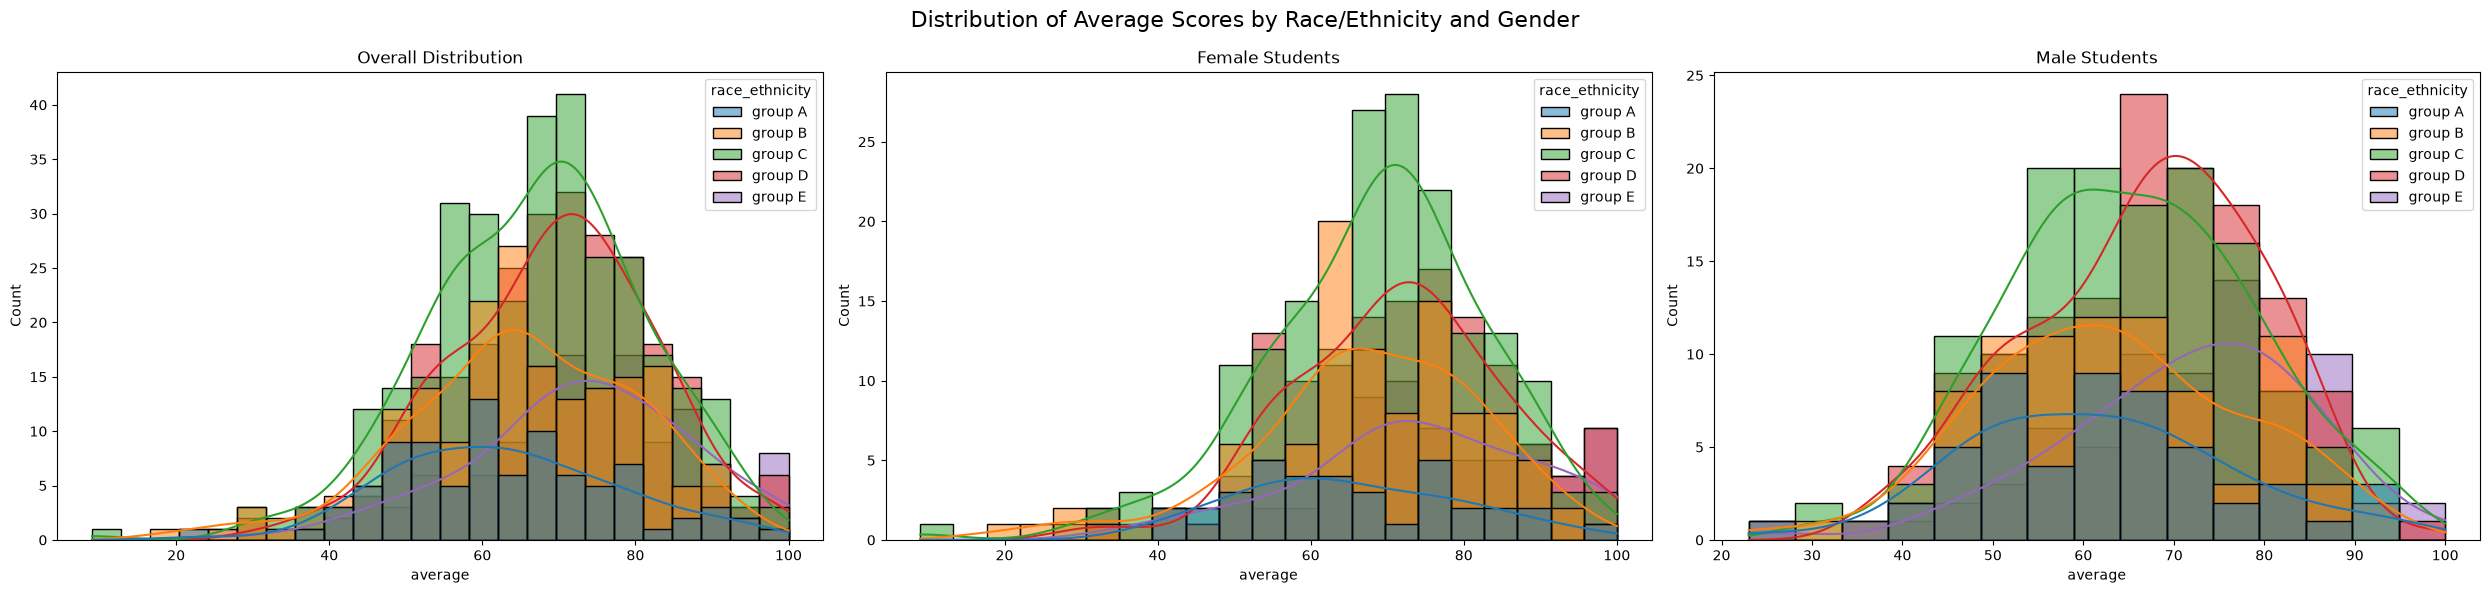

In [55]:
fig, axs = plt.subplots(1, 3, figsize=(25, 6))

# Plot 1: Overall population distribution by race/ethnicity
sns.histplot(data=df, x='average', kde=True, hue='race_ethnicity', hue_order=sorted(df['race_ethnicity'].dropna().unique()), ax=axs[0])
axs[0].set_title('Overall Distribution')

# Plot 2: Female students distribution by race/ethnicity
sns.histplot(data=df[df.gender == 'female'], x='average', kde=True, hue='race_ethnicity', hue_order=sorted(df['race_ethnicity'].dropna().unique()), ax=axs[1])
axs[1].set_title('Female Students')

# Plot 3: Male students distribution by race/ethnicity
sns.histplot(data=df[df.gender == 'male'], x='average', kde=True, hue='race_ethnicity', hue_order=sorted(df['race_ethnicity'].dropna().unique()), ax=axs[2])
axs[2].set_title('Male Students')

# Add overall title and optimize layout
plt.suptitle('Distribution of Average Scores by Race/Ethnicity and Gender', fontsize=16)
plt.tight_layout()
plt.show()

#####  Insights
- Students of group A and group B tend to perform poorly in exams.
- Students of group A and group B tend to perform poorly in exam irrespective of whether they are male or female

#### 4.2 Maximumum score of students in all three subjects

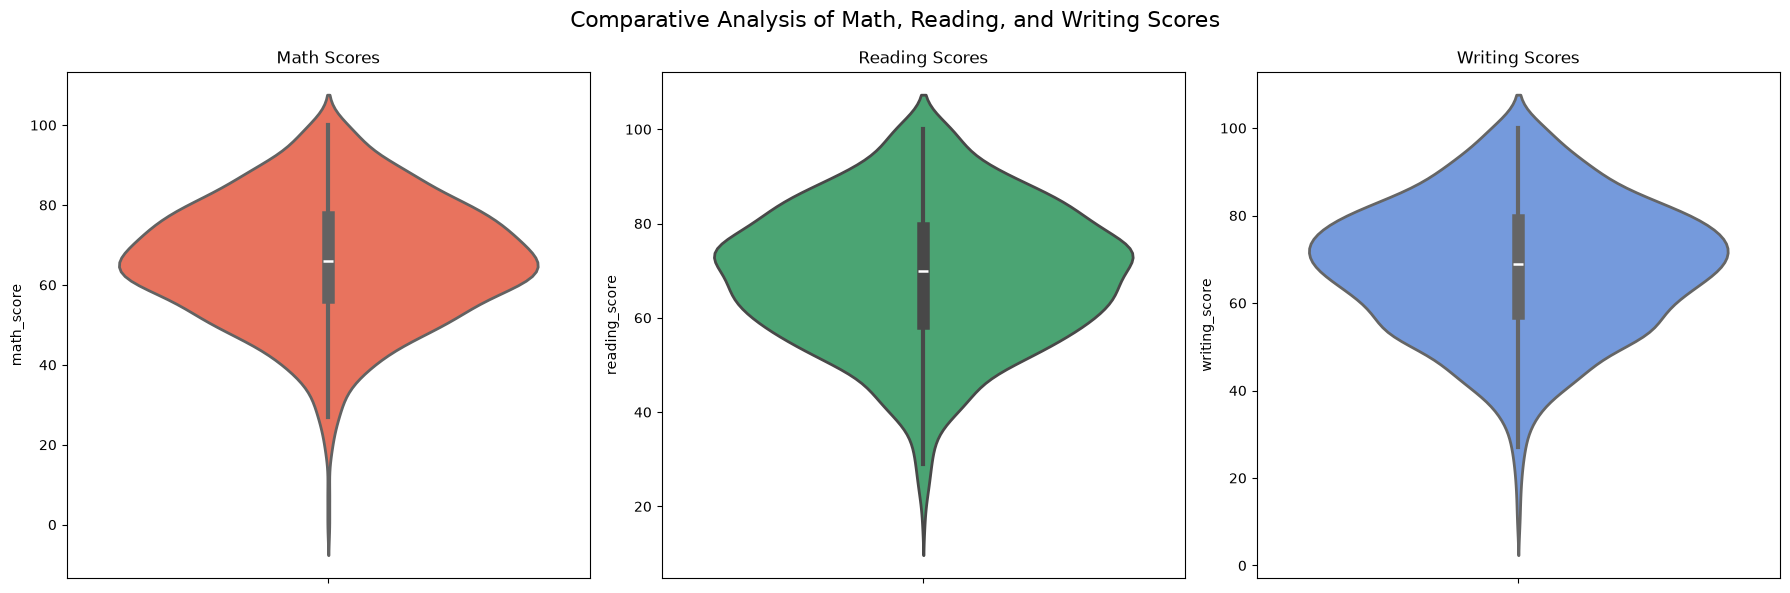

In [56]:
fig, axs = plt.subplots(1, 3, figsize=(18, 6))

# Plot 1: Math scores distribution and variance
sns.violinplot(y='math_score', data=df, color='tomato', linewidth=2, ax=axs[0])
axs[0].set_title('Math Scores')

# Plot 2: Reading scores distribution and variance
sns.violinplot(y='reading_score', data=df, color='mediumseagreen', linewidth=2, ax=axs[1])
axs[1].set_title('Reading Scores')

# Plot 3: Writing scores distribution and variance
sns.violinplot(y='writing_score', data=df, color='cornflowerblue', linewidth=2, ax=axs[2])
axs[2].set_title('Writing Scores')

plt.suptitle('Comparative Analysis of Math, Reading, and Writing Scores', fontsize=16)
plt.tight_layout()
plt.show()

#### Insights
- From the above three plots its clearly visible that most of the students score in between 60-80 in Maths whereas in reading and writing most of them score from 50-80

#### 4.3 Multivariate analysis using pyplot

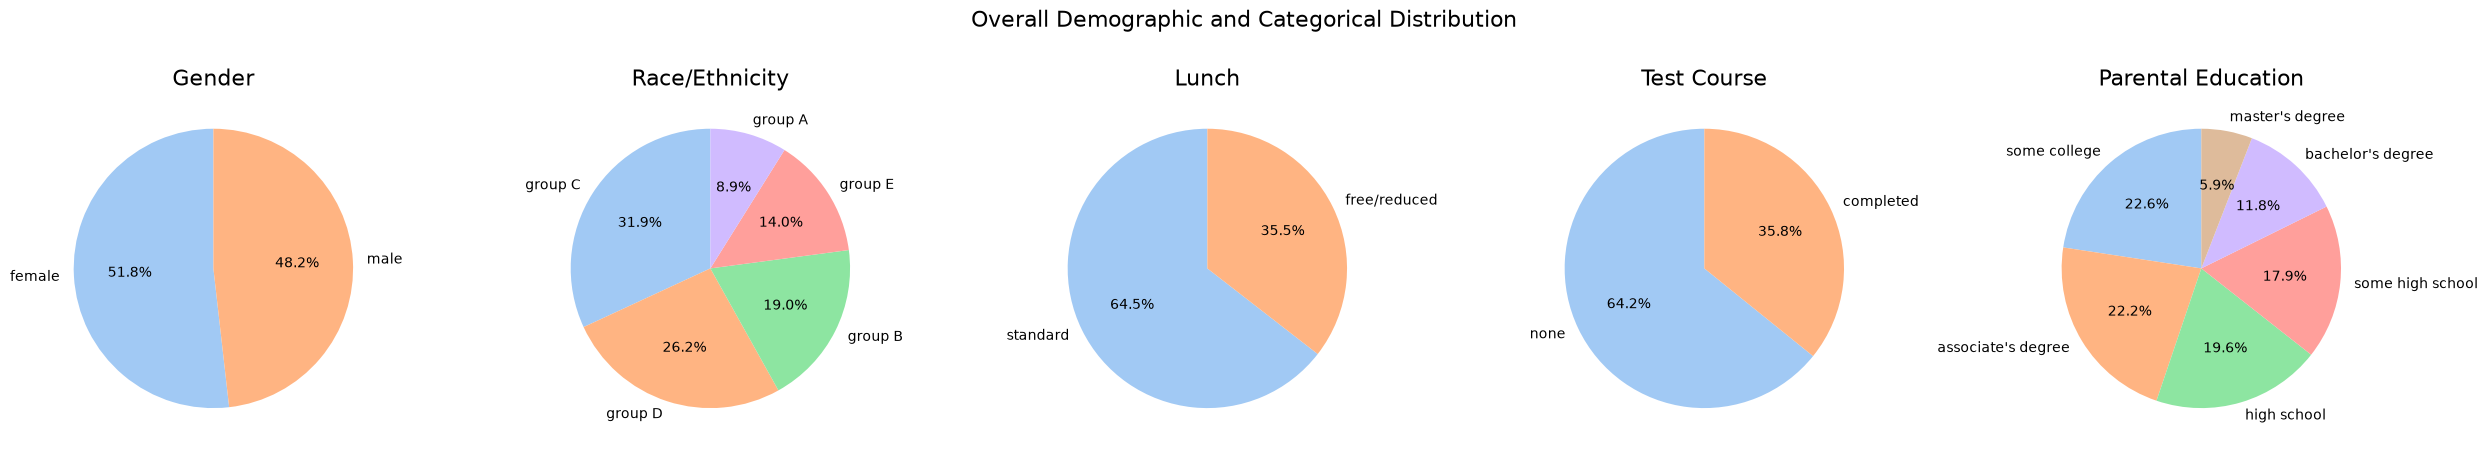

In [57]:
fig, axs = plt.subplots(1, 5, figsize=(25, 5))

# Plot 1: Gender distribution
gender_counts = df['gender'].value_counts()
axs[0].pie(gender_counts, labels=gender_counts.index, colors=sns.color_palette('pastel'), autopct='%1.1f%%', startangle=90)
axs[0].set_title('Gender', fontsize=16)

# Plot 2: Race/Ethnicity distribution
race_counts = df['race_ethnicity'].value_counts()
axs[1].pie(race_counts, labels=race_counts.index, colors=sns.color_palette('pastel'), autopct='%1.1f%%', startangle=90)
axs[1].set_title('Race/Ethnicity', fontsize=16)

# Plot 3: Lunch type distribution
lunch_counts = df['lunch'].value_counts()
axs[2].pie(lunch_counts, labels=lunch_counts.index, colors=sns.color_palette('pastel'), autopct='%1.1f%%', startangle=90)
axs[2].set_title('Lunch', fontsize=16)

# Plot 4: Test preparation course status
prep_counts = df['test_preparation_course'].value_counts()
axs[3].pie(prep_counts, labels=prep_counts.index, colors=sns.color_palette('pastel'), autopct='%1.1f%%', startangle=90)
axs[3].set_title('Test Course', fontsize=16)

# Plot 5: Parental level of education distribution
edu_counts = df['parental_level_of_education'].value_counts()
axs[4].pie(edu_counts, labels=edu_counts.index, colors=sns.color_palette('pastel'), autopct='%1.1f%%', startangle=90)
axs[4].set_title('Parental Education', fontsize=16)

plt.suptitle('Overall Demographic and Categorical Distribution', fontsize=16)
plt.tight_layout()
plt.show()

#####  Insights
- Number of Male and Female students is almost equal
- Number students are greatest in Group C
- Number of students who have standard lunch are greater
- Number of students who have not enrolled in any test preparation course is greater
- Number of students whose parental education is "Some College" is greater followed closely by "Associate's Degree"

#### 4.4 Feature Wise Visualization
#### 4.4.1 GENDER COLUMN
- How is distribution of Gender ?
- Is gender has any impact on student's performance ?

#### UNIVARIATE ANALYSIS ( How is distribution of Gender ? )

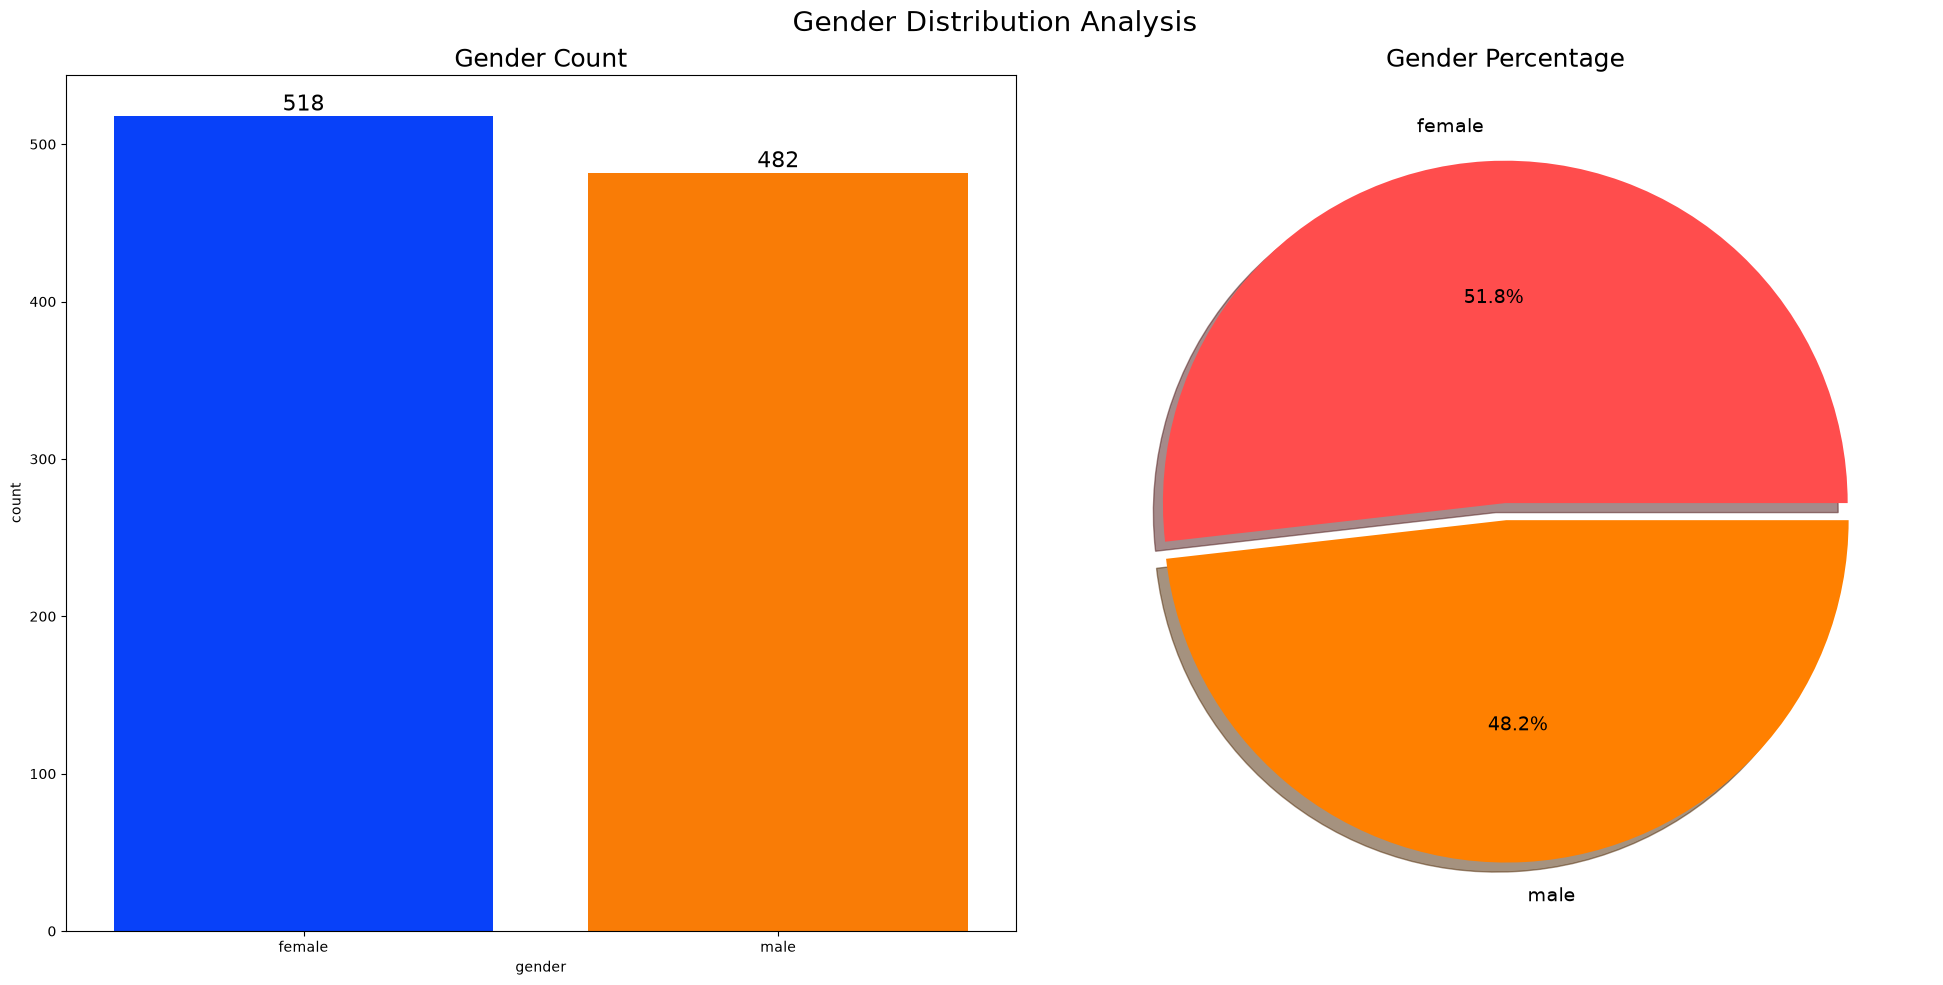

In [58]:
fig, axs = plt.subplots(1, 2, figsize=(20, 10))

# Plot 1: Count plot for gender distribution
sns.countplot(x='gender', data=df, palette='bright', ax=axs[0], saturation=0.95)
axs[0].set_title('Gender Count', fontsize=18)
for container in axs[0].containers:
    axs[0].bar_label(container, color='black', size=16)

# Plot 2: Pie chart for gender percentage distribution
gender_counts = df['gender'].value_counts()
axs[1].pie(
    x=gender_counts, 
    labels=gender_counts.index, 
    explode=[0, 0.05], 
    autopct='%1.1f%%', 
    shadow=True, 
    colors=['#ff4d4d', '#ff8000'],
    textprops={'fontsize': 14}
)
axs[1].set_title('Gender Percentage', fontsize=18)

plt.suptitle('Gender Distribution Analysis', fontsize=20)
plt.tight_layout()
plt.show()

#### Insights 
- Gender has balanced data with female students are 518 (48%) and male students are 482 (52%) 

#### BIVARIATE ANALYSIS ( Is gender has any impact on student's performance ? ) 

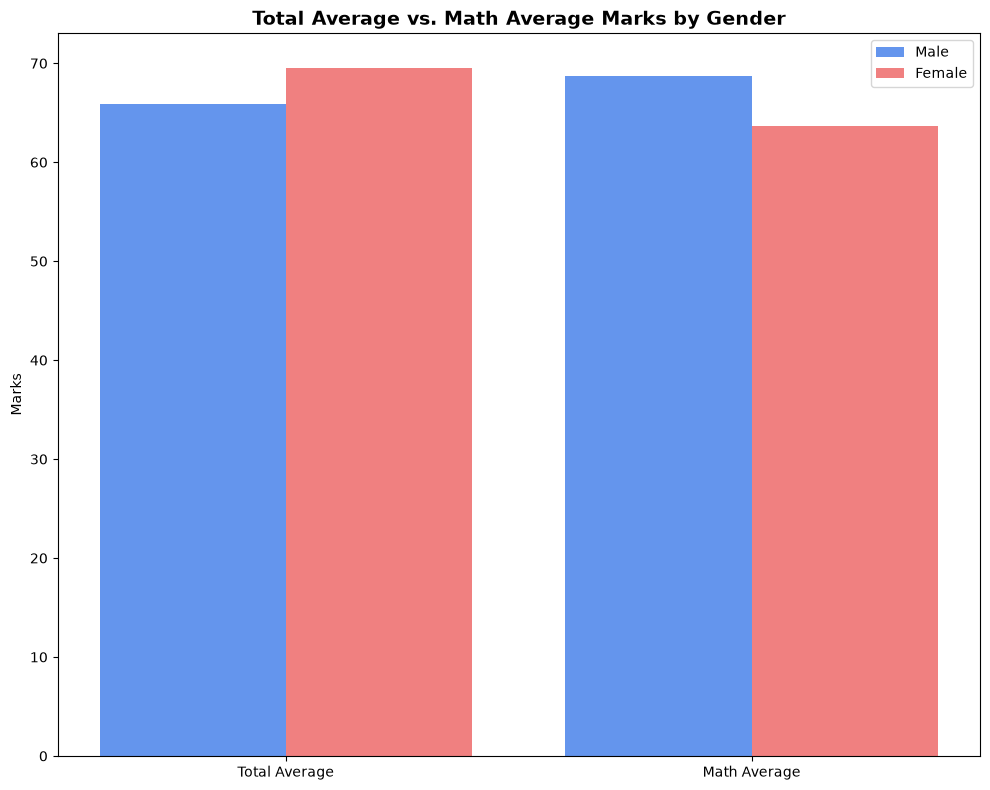

In [59]:
# Group by gender and compute the mean of numeric columns
gender_group = df.groupby('gender').mean(numeric_only=True)

# Set up the figure and axis
fig, ax = plt.subplots(figsize=(10, 8))

X = ['Total Average', 'Math Average']

# Extract values dynamically
# Note: index 0 = female, index 1 = male (if sorted alphabetically or ordered)
female_scores = [gender_group.loc['female', 'average'], gender_group.loc['female', 'math_score']]
male_scores = [gender_group.loc['male', 'average'], gender_group.loc['male', 'math_score']]

X_axis = np.arange(len(X))

# Plot bars for male and female scores
ax.bar(X_axis - 0.2, male_scores, 0.4, label='Male', color='cornflowerblue')
ax.bar(X_axis + 0.2, female_scores, 0.4, label='Female', color='lightcoral')

# Configure axes, labels, and title
ax.set_xticks(X_axis)
ax.set_xticklabels(X)
ax.set_ylabel('Marks')
ax.set_title('Total Average vs. Math Average Marks by Gender', fontweight='bold', fontsize=14)
ax.legend()

plt.tight_layout()
plt.show()

#### Insights 
- On an average females have a better overall score than men.
- whereas males have scored higher in Maths.

#### 4.4.2 RACE/EHNICITY COLUMN
- How is Group wise distribution ?
- Is Race/Ehnicity has any impact on student's performance ?

#### UNIVARIATE ANALYSIS ( How is Group wise distribution ?)

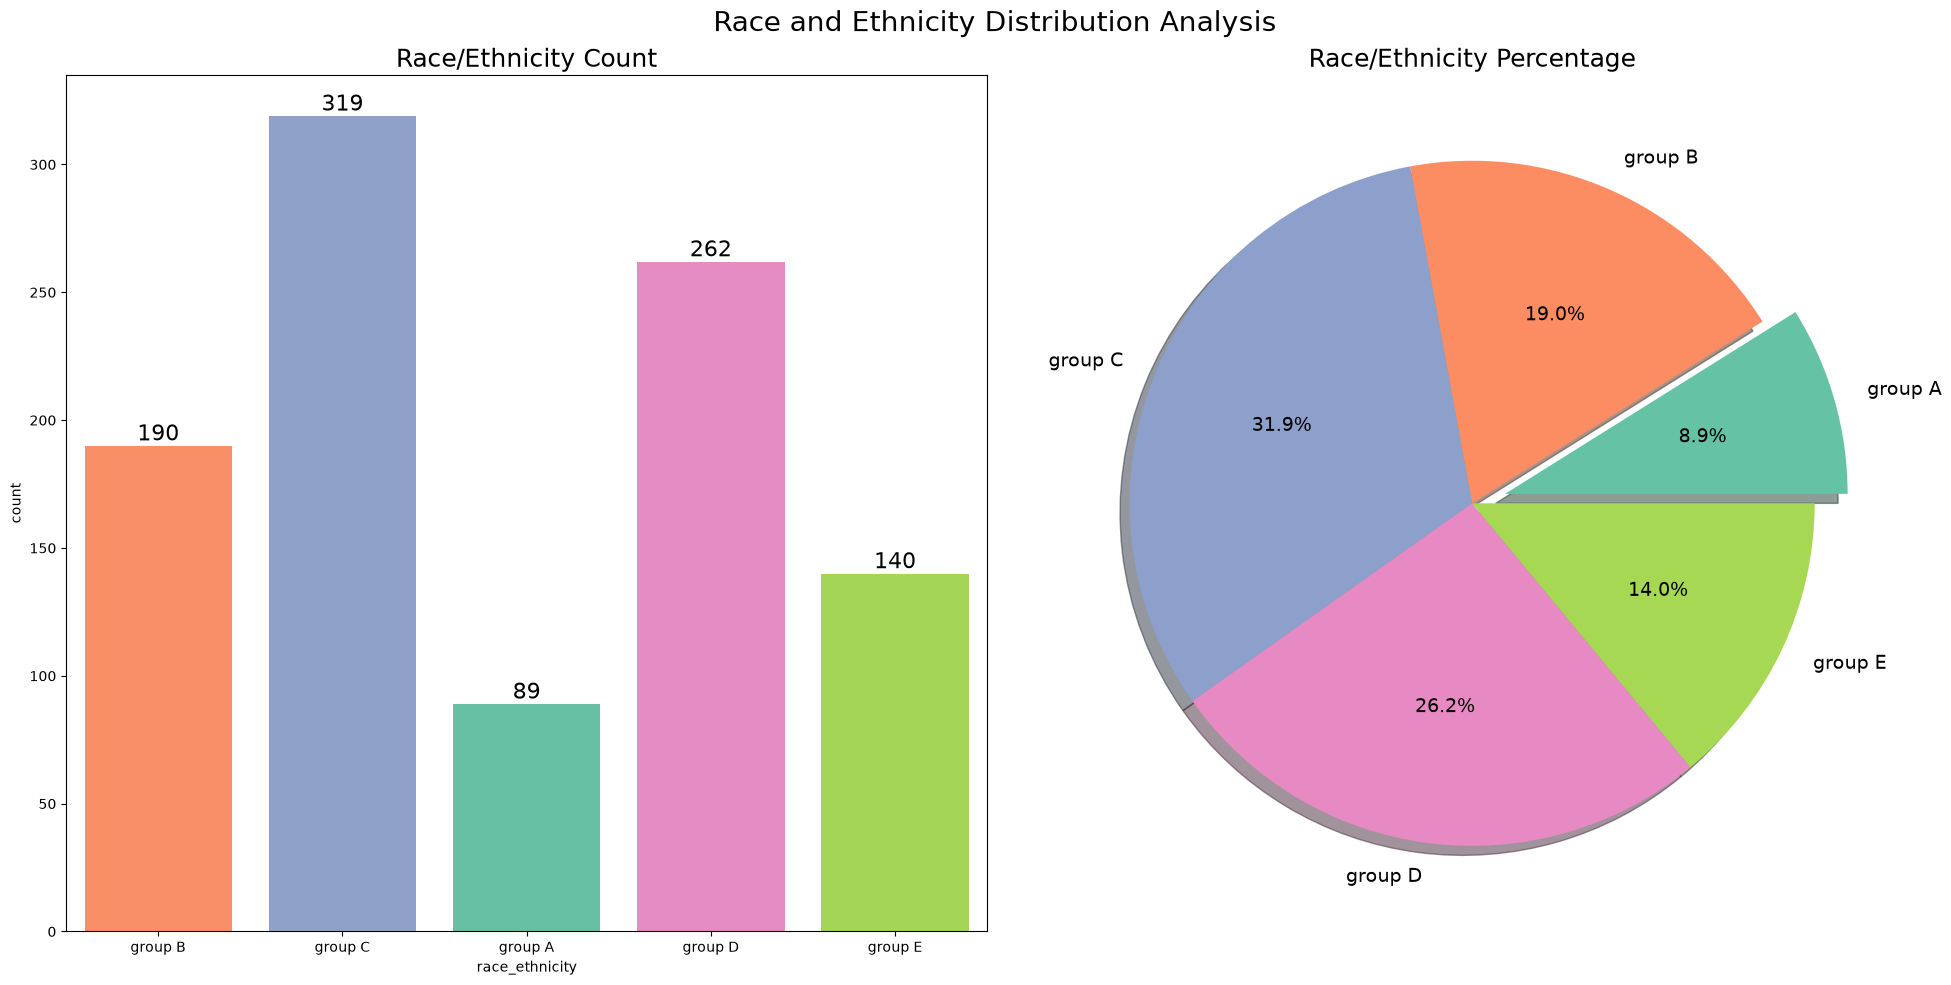

In [65]:
# Create a consistent color mapping for each race/ethnicity group
categories = sorted(df['race_ethnicity'].dropna().unique())
color_palette = sns.color_palette('Set2', len(categories))
palette_dict = dict(zip(categories, color_palette))

fig, axs = plt.subplots(1, 2, figsize=(20, 10))

# Plot 1: Count plot for race/ethnicity distribution
# We map the category colors to the bars using hue and palette
sns.countplot(
    x='race_ethnicity', 
    data=df, 
    hue='race_ethnicity',
    palette=palette_dict, 
    legend=False,
    ax=axs[0], 
    saturation=0.95
)
axs[0].set_title('Race/Ethnicity Count', fontsize=18)
for container in axs[0].containers:
    axs[0].bar_label(container, color='black', size=16)

# Plot 2: Pie chart using the exact same colors assigned by category
race_counts = df['race_ethnicity'].value_counts().sort_index()
# Map colors to match the sorted index order
pie_colors = [palette_dict[cat] for cat in race_counts.index]

axs[1].pie(
    x=race_counts, 
    labels=race_counts.index, 
    explode=[0.1, 0, 0, 0, 0], 
    autopct='%1.1f%%', 
    shadow=True, 
    colors=pie_colors,
    textprops={'fontsize': 14}
)
axs[1].set_title('Race/Ethnicity Percentage', fontsize=18)

plt.suptitle('Race and Ethnicity Distribution Analysis', fontsize=20)
plt.tight_layout()
plt.show()   

#### Insights 
- Most of the student belonging from group C /group D.
- Lowest number of students belong to groupA.

#### BIVARIATE ANALYSIS ( Is Race/Ehnicity has any impact on student's performance ? )

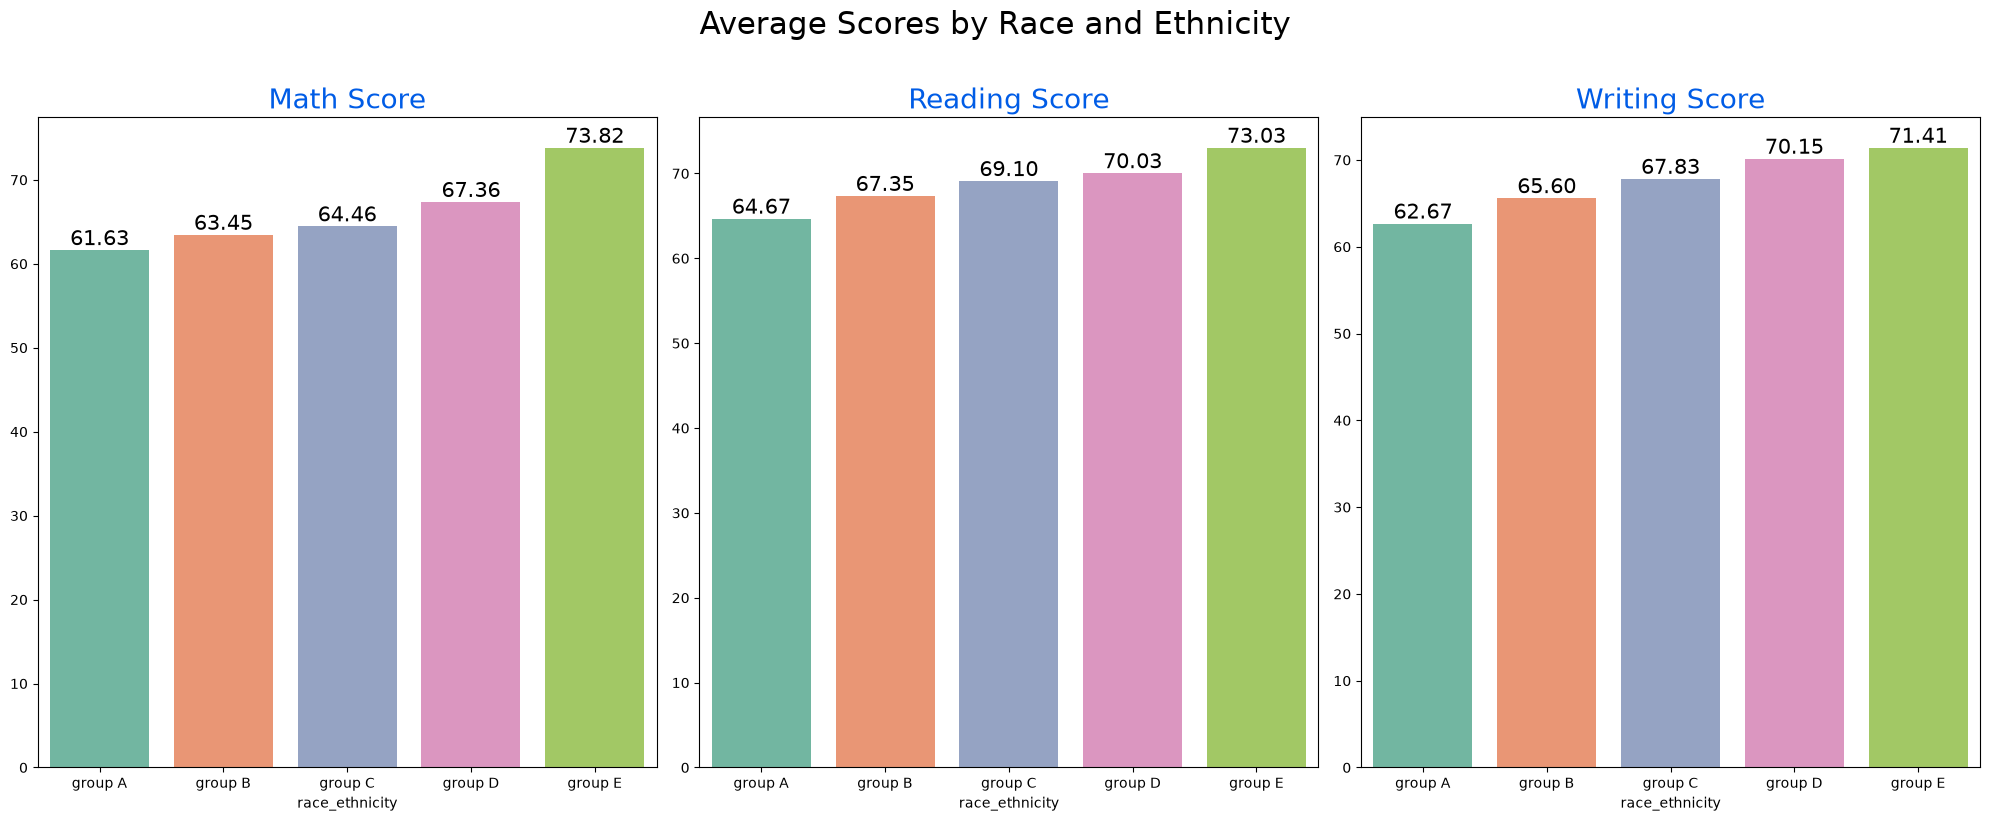

In [67]:
# Group data by race/ethnicity
group_data2 = df.groupby('race_ethnicity')

fig, axs = plt.subplots(1, 3, figsize=(20, 8))

# Plot 1: Math score mean by race/ethnicity
sns.barplot(
    x=group_data2['math_score'].mean().index, 
    y=group_data2['math_score'].mean().values, 
    hue=group_data2['math_score'].mean().index,
    palette=palette_dict, 
    legend=False,
    ax=axs[0]
)
axs[0].set_title('Math Score', color='#005ce6', size=20)
for container in axs[0].containers:
    axs[0].bar_label(container, color='black', size=15, fmt='%.2f')

# Plot 2: Reading score mean by race/ethnicity
sns.barplot(
    x=group_data2['reading_score'].mean().index, 
    y=group_data2['reading_score'].mean().values, 
    hue=group_data2['reading_score'].mean().index,
    palette=palette_dict, 
    legend=False,
    ax=axs[1]
)
axs[1].set_title('Reading Score', color='#005ce6', size=20)
for container in axs[1].containers:
    axs[1].bar_label(container, color='black', size=15, fmt='%.2f')

# Plot 3: Writing score mean by race/ethnicity
sns.barplot(
    x=group_data2['writing_score'].mean().index, 
    y=group_data2['writing_score'].mean().values, 
    hue=group_data2['writing_score'].mean().index,
    palette=palette_dict, 
    legend=False,
    ax=axs[2]
)
axs[2].set_title('Writing Score', color='#005ce6', size=20)
for container in axs[2].containers:
    axs[2].bar_label(container, color='black', size=15, fmt='%.2f')

plt.suptitle('Average Scores by Race and Ethnicity', fontsize=22, y=1.02)
plt.tight_layout()
plt.show()

#### Insights 
- Group E students have scored the highest marks. 
- Group A students have scored the lowest marks. 
- Students from a lower Socioeconomic status have a lower avg in all course subjects

#### 4.4.3 PARENTAL LEVEL OF EDUCATION COLUMN
- What is educational background of student's parent ?
- Is parental education has any impact on student's performance ?

#### UNIVARIATE ANALYSIS ( What is educational background of student's parent ? )

In [ ]:
plt.rcParams['figure.figsize'] = (15, 9)
plt.style.use('fivethirtyeight')
sns.countplot(df['parental level of education'], palette = 'Blues')
plt.title('Comparison of Parental Education', fontweight = 30, fontsize = 20)
plt.xlabel('Degree')
plt.ylabel('count')
plt.show()

#### Insights 
- Largest number of parents are from some college.

#### BIVARIATE ANALYSIS ( Is parental education has any impact on student's performance ? )

In [ ]:
df.groupby('parental level of education').agg('mean').plot(kind='barh',figsize=(10,10))
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)
plt.show()

#### Insights 
- The score of student whose parents possess master and bachelor level education are higher than others.

#### 4.4.4 LUNCH COLUMN 
- Which type of lunch is most common amoung students ?
- What is the effect of lunch type on test results?


#### UNIVARIATE ANALYSIS ( Which type of lunch is most common amoung students ? )

In [ ]:
plt.rcParams['figure.figsize'] = (15, 9)
plt.style.use('seaborn-talk')
sns.countplot(df['lunch'], palette = 'PuBu')
plt.title('Comparison of different types of lunch', fontweight = 30, fontsize = 20)
plt.xlabel('types of lunch')
plt.ylabel('count')
plt.show()

#### Insights 
- Students being served Standard lunch was more than free lunch

#### BIVARIATE ANALYSIS (  Is lunch type intake has any impact on student's performance ? )

In [ ]:
f,ax=plt.subplots(1,2,figsize=(20,8))
sns.countplot(x=df['parental level of education'],data=df,palette = 'bright',hue='test preparation course',saturation=0.95,ax=ax[0])
ax[0].set_title('Students vs test preparation course ',color='black',size=25)
for container in ax[0].containers:
    ax[0].bar_label(container,color='black',size=20)
    
sns.countplot(x=df['parental level of education'],data=df,palette = 'bright',hue='lunch',saturation=0.95,ax=ax[1])
for container in ax[1].containers:
    ax[1].bar_label(container,color='black',size=20)   

#### Insights 
- Students who get Standard Lunch tend to perform better than students who got free/reduced lunch

#### 4.4.5 TEST PREPARATION COURSE COLUMN 
- Which type of lunch is most common amoung students ?
- Is Test prepration course has any impact on student's performance ?

#### BIVARIATE ANALYSIS ( Is Test prepration course has any impact on student's performance ? )

In [ ]:
plt.figure(figsize=(12,6))
plt.subplot(2,2,1)
sns.barplot (x=df['lunch'], y=df['math score'], hue=df['test preparation course'])
plt.subplot(2,2,2)
sns.barplot (x=df['lunch'], y=df['reading score'], hue=df['test preparation course'])
plt.subplot(2,2,3)
sns.barplot (x=df['lunch'], y=df['writing score'], hue=df['test preparation course'])

#### Insights  
- Students who have completed the Test Prepration Course have scores higher in all three categories than those who haven't taken the course

#### 4.4.6 CHECKING OUTLIERS

In [ ]:
plt.subplots(1,4,figsize=(16,5))
plt.subplot(141)
sns.boxplot(df['math score'],color='skyblue')
plt.subplot(142)
sns.boxplot(df['reading score'],color='hotpink')
plt.subplot(143)
sns.boxplot(df['writing score'],color='yellow')
plt.subplot(144)
sns.boxplot(df['average'],color='lightgreen')
plt.show()

#### 4.4.7 MUTIVARIATE ANALYSIS USING PAIRPLOT

In [ ]:
sns.pairplot(df,hue = 'gender')
plt.show()

#### Insights
- From the above plot it is clear that all the scores increase linearly with each other.

### 5. Conclusions
- Student's Performance is related with lunch, race, parental level education
- Females lead in pass percentage and also are top-scorers
- Student's Performance is not much related with test preparation course
- Finishing preparation course is benefitial.